# Regresi Linear dan Pemisahan Data (Train-Test Split)

Course 2: Supervised Learning

Di notebook ini saya mencoba membuat model regresi linear untuk memprediksi harga rumah. Yang dibandingkan: data dengan dan tanpa one-hot encoding, lalu pengaruh scaling terhadap error di data test.

## Dataset

Datanya `Ames_Housing_Sales.csv`, penjualan rumah di Ames, Iowa (versi dari kompetisi Kaggle "House Prices"). Ada 79 kolom fitur dan satu kolom target, `SalePrice`. Dibaca langsung dari link, jadi tidak perlu diunduh:

https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/data/Ames_Housing_Sales.csv

## 1. Import library dan baca data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

sns.set_style("whitegrid")

In [2]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/data/Ames_Housing_Sales.csv"
data = pd.read_csv(URL)
data.head()

,1stFlrSF,2ndFlrSF,3SsnPorch,Alley,BedroomAbvGr,BldgType,BsmtCond,BsmtExposure,BsmtFinSF1,BsmtFinSF2,...,ScreenPorch,Street,TotRmsAbvGrd,TotalBsmtSF,Utilities,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold,SalePrice
0,856.0,854.0,0.0,NaN,3,1Fam,TA,No,706.0,0.0,...,0.0,Pave,8,856.0,AllPub,0.0,2003,2003,2008,208500.0
1,1262.0,0.0,0.0,NaN,3,1Fam,TA,Gd,978.0,0.0,...,0.0,Pave,6,1262.0,AllPub,298.0,1976,1976,2007,181500.0
2,920.0,866.0,0.0,NaN,3,1Fam,TA,Mn,486.0,0.0,...,0.0,Pave,6,920.0,AllPub,0.0,2001,2002,2008,223500.0
3,961.0,756.0,0.0,NaN,3,1Fam,Gd,No,216.0,0.0,...,0.0,Pave,7,756.0,AllPub,0.0,1915,1970,2006,140000.0
4,1145.0,1053.0,0.0,NaN,4,1Fam,TA,Av,655.0,0.0,...,0.0,Pave,9,1145.0,AllPub,192.0,2000,2000,2008,250000.0


### Latihan 1: ukuran data dan tipe kolom

In [3]:
print("ukuran data:", data.shape)
data.dtypes.value_counts()

ukuran data: (1379, 80)


,count
object,43
float64,21
int64,16


Ada tiga jenis tipe: integer, float, dan object (teks/kategorikal). Kolom object inilah yang nanti perlu di-encode sebelum masuk ke regresi linear.

## 2. Berapa kolom yang muncul kalau semua kategorikal di-one-hot encode?

One-hot encoding mengubah satu kolom kategorikal dengan `n` kategori menjadi `n-1` kolom baru (satu kategori dibuang supaya tidak redundan). Kolom yang isinya cuma satu nilai tidak perlu di-encode. Aku hitung dulu perkiraannya sebelum benar-benar di-encode.

In [4]:
kolom_kat = data.select_dtypes(exclude="number").columns
jumlah_kategori = data[kolom_kat].nunique().sort_values(ascending=False)
jumlah_kategori.head(10)

,0
Neighborhood,25
Exterior2nd,16
Exterior1st,14
SaleType,9
Condition1,9
RoofMatl,8
HouseStyle,8
Condition2,8
Functional,7
GarageType,6


In [5]:
perlu_encode = jumlah_kategori[jumlah_kategori > 1]
kolom_baru = int((perlu_encode - 1).sum())

print("kolom kategorikal            :", len(kolom_kat))
print("kolom one-hot yang terbentuk :", kolom_baru)

kolom kategorikal            : 43
kolom one-hot yang terbentuk : 204


Jumlah kolomnya bertambah cukup banyak untuk dataset yang barisnya cuma sekitar seribuan, ini yang nanti berpengaruh ke overfitting.

## 3. Buat dua versi data

- `data_ohe`: semua kolom kategorikal di-one-hot encode (pakai `pd.get_dummies`, kolom aslinya otomatis hilang)
- `data_num`: kolom kategorikal dibuang, hanya sisa kolom numerik

In [6]:
data_ohe = pd.get_dummies(data, columns=list(kolom_kat), drop_first=True, dtype=int)
data_num = data.drop(columns=kolom_kat)

print("tanpa encoding :", data_num.shape)
print("one-hot        :", data_ohe.shape)
print("kolom tambahan :", data_ohe.shape[1] - data_num.shape[1], "| hitungan sebelumnya:", kolom_baru)

tanpa encoding : (1379, 37)
one-hot        : (1379, 241)
kolom tambahan : 204 | hitungan sebelumnya: 204


## 4. Train-test split dan perbandingan error

Kedua versi data dipisah dengan `random_state` yang sama supaya baris yang masuk train dan test identik.

In [7]:
def pisah(df, target="SalePrice"):
    X = df.drop(columns=target)
    y = df[target]
    return train_test_split(X, y, test_size=0.3, random_state=42)

Xtr_num, Xte_num, ytr_num, yte_num = pisah(data_num)
Xtr_ohe, Xte_ohe, ytr_ohe, yte_ohe = pisah(data_ohe)

print("index train sama:", (Xtr_num.index == Xtr_ohe.index).all())
print("train:", len(Xtr_num), "| test:", len(Xte_num))

index train sama: True
train: 965 | test: 414


In [8]:
def mse_train_test(Xa, ya, Xb, yb):
    model = LinearRegression().fit(Xa, ya)
    return {"train": mean_squared_error(ya, model.predict(Xa)),
            "test": mean_squared_error(yb, model.predict(Xb))}

hasil = pd.DataFrame({
    "tanpa encoding": mse_train_test(Xtr_num, ytr_num, Xte_num, yte_num),
    "one-hot": mse_train_test(Xtr_ohe, ytr_ohe, Xte_ohe, yte_ohe),
})
hasil.round(0)

,tanpa encoding,one-hot
train,1.131507e+09,3.442266e+08
test,1.372182e+09,2.845130e+09


Cara membaca tabelnya: model yang bagus punya error train dan test yang dekat. Kalau error train kecil tapi error test jauh lebih besar, modelnya overfitting (menghafal data latih). Model one-hot punya ratusan fitur tambahan dibanding jumlah data latih, jadi lebih rawan overfit. Masalah inilah yang nanti diatasi dengan regularisasi di materi berikutnya.

## 5. Scaling

Scaling hanya dikenakan pada kolom float (kolom hasil one-hot tidak perlu). Aturan pentingnya: scaler di-`fit` hanya pada data train, lalu dipakai untuk mengubah data train dan test. Supaya aturan itu terjaga otomatis, aku pakai `ColumnTransformer` di dalam `Pipeline`.

Cek dulu kemiringan (skewness) kolom float di data train:

In [9]:
kolom_float = Xtr_num.select_dtypes("float").columns.tolist()
Xtr_num[kolom_float].skew().sort_values(ascending=False).head(8).round(2)

,0
MiscVal,26.92
PoolArea,15.78
LotArea,11.50
LowQualFinSF,11.21
3SsnPorch,10.15
ScreenPorch,4.60
BsmtFinSF2,4.47
EnclosedPorch,3.22


Beberapa kolom cukup miring, tapi di latihan ini aku fokus ke efek scaler saja dan tidak melakukan transformasi log.

In [10]:
daftar_scaler = {"standard": StandardScaler, "minmax": MinMaxScaler, "maxabs": MaxAbsScaler}
daftar_data = {
    "tanpa encoding": (Xtr_num, ytr_num, Xte_num, yte_num),
    "one-hot": (Xtr_ohe, ytr_ohe, Xte_ohe, yte_ohe),
}

baris = []
for nama_data, (Xa, ya, Xb, yb) in daftar_data.items():
    hasil_scaler = {}
    for nama_sc, kelas in daftar_scaler.items():
        pipa = Pipeline([
            ("scale", ColumnTransformer([("float", kelas(), kolom_float)], remainder="passthrough")),
            ("lr", LinearRegression()),
        ])
        pipa.fit(Xa, ya)
        hasil_scaler[nama_sc] = mean_squared_error(yb, pipa.predict(Xb))
    baris.append(pd.Series(hasil_scaler, name=nama_data))

pd.DataFrame(baris).round(0)

,standard,minmax,maxabs
tanpa encoding,1.372182e+09,1.372182e+09,1.372182e+09
one-hot,2.845130e+09,2.845130e+09,2.845130e+09


Untuk regresi linear biasa, scaling hampir tidak mengubah prediksi karena model ini tidak sensitif terhadap skala fitur, jadi angka antar scaler seharusnya sangat dekat. Scaling baru berpengaruh besar saat ada regularisasi atau gradient descent (dibahas di notebook berikutnya).

## 6. Prediksi vs nilai sebenarnya

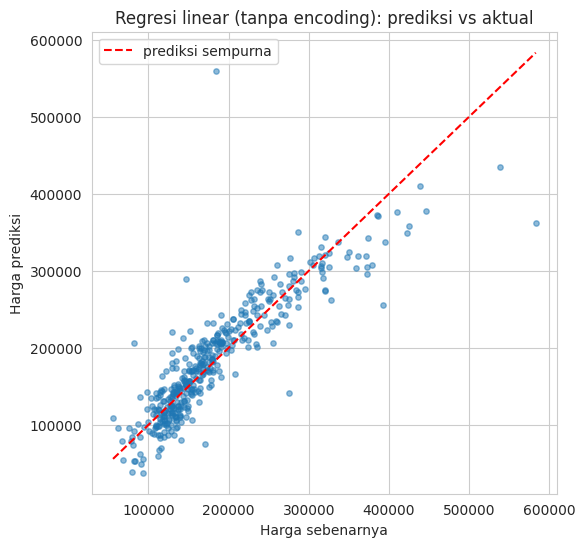

In [11]:
lr = LinearRegression().fit(Xtr_num, ytr_num)
pred = lr.predict(Xte_num)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(yte_num, pred, s=15, alpha=0.5)
batas = [yte_num.min(), yte_num.max()]
ax.plot(batas, batas, "r--", label="prediksi sempurna")
ax.set(xlabel="Harga sebenarnya", ylabel="Harga prediksi",
       title="Regresi linear (tanpa encoding): prediksi vs aktual")
ax.legend()
plt.show()

Titik yang dekat garis putus-putus berarti prediksinya akurat. Makin jauh dari garis, makin besar kesalahannya.